# Whole-section molecular comparison

Compare six young and six old mouse hearts using all measured pixels. The
extraction already calculated each mouse's mean spectrum at native resolution.
Summing those means into a common mass grid gives the same result as binning
every pixel spectrum and then averaging. Each mouse receives equal weight in
the comparison.

The ranking is descriptive. A mass window may contain multiple signals, and
whole-section averages can reflect differences in which tissue was measured.
Use the ranked windows to choose full-pixel maps for review.

In [1]:
import json
import os
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

root = Path.cwd().resolve()
if not (root / "pyproject.toml").exists():
    root = root.parent
assert (root / "pyproject.toml").exists(), "Open the notebook from the repository."
sys.path.insert(0, str(root / "src"))
from cardiac_aging.inspection import load_config

config = load_config(root)
# Override this path with CARDIAC_MSI_FEATURES if the extracted data move.
default_features = Path.home() / "Documents/Codex/2026-11-03/can-x20/work/full-msi"
features = Path(os.environ.get("CARDIAC_MSI_FEATURES", str(default_features)))
results = root / config["results_dir"]
results.mkdir(parents=True, exist_ok=True)
samples = pd.read_csv(root / config["sample_sheet"], dtype={"measurement_id": str})
assert samples["animal_id"].nunique() == len(samples) == 12
assert samples["age_group"].value_counts().to_dict() == {"young": 6, "old": 6}

mean_spectra, coverage = [], []
common_edges = None
for sample in samples.itertuples(index=False):
    folder = features / sample.measurement_id
    info = json.loads((folder / "summary.json").read_text(encoding="utf-8"))
    if (info["preview"] or info["pixels_processed"] != info["pixels_declared"]
            or info["measurement_id"] != sample.measurement_id
            or info["source"] != sample.imzml_filename):
        raise ValueError(f"Unexpected extraction metadata for {sample.measurement_id}")
    with np.load(folder / "axes_and_native_mean.npz") as arrays:
        mz, mean, edges = arrays["mz"], arrays["native_mean"], arrays["bin_edges"]
        if common_edges is None:
            common_edges = edges
        elif not np.array_equal(edges, common_edges):
            raise ValueError(f"Mass grid differs for {sample.measurement_id}")
        starts = np.searchsorted(mz, edges[:-1])
        if (starts[0] != 0 or starts[-1] >= len(mz) or not np.all(np.diff(starts) > 0)
                or mz[-1] != edges[-1] or not np.isfinite(mean).all()):
            raise ValueError(f"Invalid mass axis or spectrum for {sample.measurement_id}")
        binned_mean = np.add.reduceat(mean, starts)
        np.testing.assert_allclose(binned_mean.sum(), mean.sum(), rtol=1e-12)
        mean_spectra.append(binned_mean)
    coverage.append(info["pixels_processed"])

intensity = np.stack(mean_spectra)
samples["pixels_used"] = coverage
display(samples[["measurement_id", "animal_id", "age_group", "pixels_used"]])
print(f"{sum(coverage):,} pixels represented in {len(samples)} mouse-level spectra.")

,measurement_id,animal_id,age_group,pixels_used
0,1465,Lux10,young,49973
1,1466,Lux11,young,67228
2,1467,Lux12,young,69540
3,1468,Lux16,young,96297
4,1469,Lux17,young,83903
5,1470,Lux18,young,71670
6,1471,Lux13,old,78259
7,1472,Lux14,old,88747
8,1473,Lux15,old,124191
9,1474,Lux19,old,101798


1,038,886 pixels represented in 12 mouse-level spectra.


In [6]:
is_old = samples["age_group"].eq("old").to_numpy()
young, old = intensity[~is_old], intensity[is_old]
young_mean, old_mean = young.mean(axis=0), old.mean(axis=0)
difference = old_mean - young_mean
pooled_sd = np.sqrt((young.var(axis=0, ddof=1) + old.var(axis=0, ddof=1)) / 2)
standardized = np.divide(difference, pooled_sd,
                         out=np.full_like(difference, np.nan), where=pooled_sd > 0)

# Check whether removing any one mouse reverses the direction.
without_one = np.vstack([
    old_mean - (young.sum(axis=0) - young) / (len(young) - 1),
    (old.sum(axis=0) - old) / (len(old) - 1) - young_mean,
])
stable = np.all(np.sign(without_one) == np.sign(difference), axis=0) & (difference != 0)
windows = pd.DataFrame({
    "mz_lower": common_edges[:-1],
    "mz_upper": common_edges[1:],
    "young_mean": young_mean,
    "old_mean": old_mean,
    "old_minus_young": difference,
    "standardized_difference": standardized,
    "direction_stable_after_leaving_one_mouse_out": stable,
})
windows["absolute_standardized_difference"] = windows["standardized_difference"].abs()
windows = windows.sort_values("absolute_standardized_difference", ascending=False)
windows.to_csv(results / "whole_section_mass_windows.csv", index=False)
np.savez(results / "whole_section_mouse_spectra.npz", measurement_ids=samples["measurement_id"].to_numpy(dtype=str),
         age_groups=samples["age_group"].to_numpy(dtype=str), bin_edges=common_edges,
         intensity=intensity, pixels_used=coverage)

# Choose separated windows to avoid displaying several adjacent bins of one peak.
selected = []
for i in windows.index[windows["standardized_difference"].notna() & windows["direction_stable_after_leaving_one_mouse_out"]]:
    if all(abs(common_edges[i] - common_edges[j]) >= 1.0 for j in selected):
        selected.append(i)
    if len(selected) == 6:
        break
display(windows.loc[selected, ["mz_lower", "mz_upper", "young_mean", "old_mean",
                               "old_minus_young", "standardized_difference"]])

,mz_lower,mz_upper,young_mean,old_mean,old_minus_young,standardized_difference
697,774.25,774.50,10.510193,13.177174,2.666981,2.188748
545,736.25,736.50,12.383017,15.098393,2.715376,1.832693
261,665.25,665.50,9.372037,11.894848,2.522811,1.672038
2026,1106.50,1106.75,6.722347,8.120476,1.398129,1.586556
169,642.25,642.50,10.259028,11.517697,1.258670,1.563167
1658,1014.50,1014.75,9.757559,12.337517,2.579958,1.517939


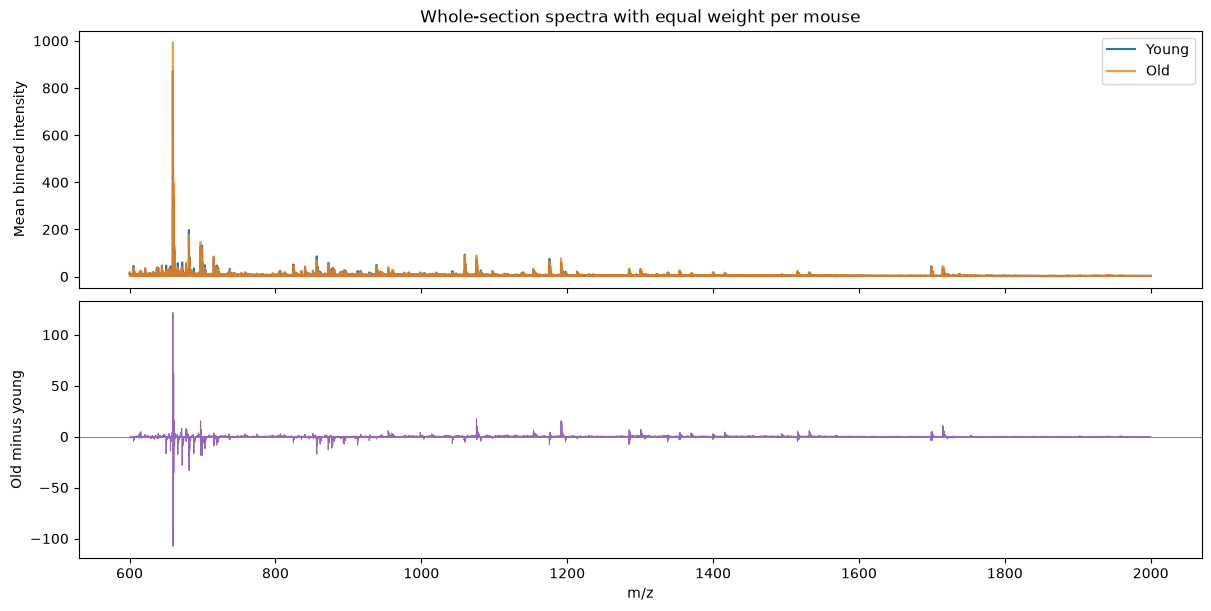

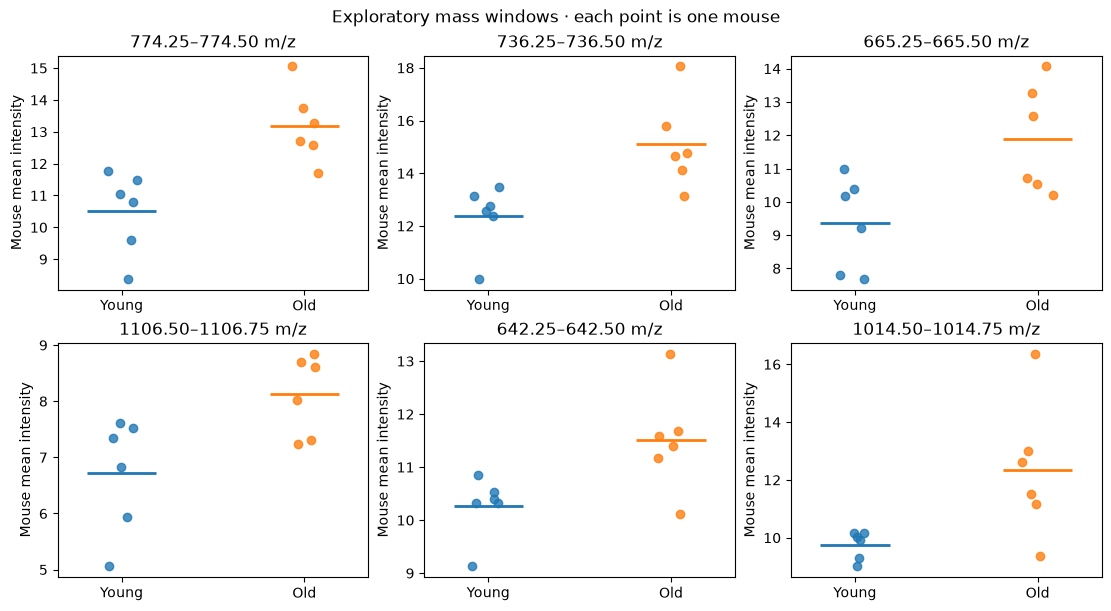

In [3]:
centers = (common_edges[:-1] + common_edges[1:]) / 2
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, layout="constrained")
axes[0].plot(centers, young_mean, color="tab:blue", label="Young")
axes[0].plot(centers, old_mean, color="tab:orange", label="Old", alpha=.8)
axes[0].set(ylabel="Mean binned intensity", title="Whole-section spectra with equal weight per mouse")
axes[0].legend()
axes[1].plot(centers, difference, color="tab:purple", linewidth=.8)
axes[1].axhline(0, color="gray", linewidth=.7)
axes[1].set(xlabel="m/z", ylabel="Old minus young")
fig.savefig(results / "whole_section_spectra.png", dpi=170)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(11, 6), layout="constrained")
rng = np.random.default_rng(42)
for ax in axes.flat:
    ax.set_visible(False)
for ax, i in zip(axes.flat, selected):
    ax.set_visible(True)
    for x, values, color in [(0, young[:, i], "tab:blue"), (1, old[:, i], "tab:orange")]:
        ax.scatter(x + rng.uniform(-.09, .09, len(values)), values, color=color, alpha=.8)
        ax.hlines(values.mean(), x - .19, x + .19, color=color, linewidth=2)
    ax.set(xticks=[0, 1], xticklabels=["Young", "Old"],
           xlim=(-.35, 1.35), title=f"{common_edges[i]:.2f}–{common_edges[i+1]:.2f} m/z",
           ylabel="Mouse mean intensity")
fig.suptitle("Exploratory mass windows · each point is one mouse")
fig.savefig(results / "whole_section_candidate_windows.png", dpi=170)
plt.show()

Candidate windows were selected on this cohort. Direction stability means the
observed contrast retains its sign when any single mouse is removed. The
standardized differences are ranking scores and do not establish a validated
age effect or molecular identity. Inspect the native peaks and the spatial
distribution before choosing windows for histology-based regional comparisons.